# Bike Rental Demand Prediction

## 1. Project Overview

Bike-sharing systems allow users to rent bicycles for short periods. Understanding daily bike rental demand helps businesses manage bicycle availability and improve operational planning.

In this project, we will analyze bike rental data, identify patterns in rental demand, and develop machine learning models to predict the daily number of bike rentals based on weather conditions, seasonal factors, and calendar information.

### Project Objectives

1. Understand and clean the daily and hourly bike rental datasets.
2. Perform Exploratory Data Analysis (EDA) to identify rental patterns and trends.
3. Study the relationship between bike rentals, weather conditions, seasons, and time.
4. Build and compare multiple regression models to predict daily bike rental counts.
5. Evaluate model performance using appropriate regression metrics.
6. Recommend a suitable model for practical use.

### Dataset Description

This project uses two datasets:

- **Daily dataset (`day.csv`):** Contains daily bike rental counts and related weather, seasonal, and calendar features.
- **Hourly dataset (`hour.csv`):** Contains hourly rental counts and related features for analyzing demand patterns throughout the day.

The daily dataset will be used to build the daily rental prediction model, while the hourly dataset will help us understand hourly rental patterns.

### Target Variable

The target variable is `cnt`, which represents the total number of bike rentals.

### Project Workflow

Data Loading → Data Cleaning → EDA → Feature Engineering → Preprocessing → Model Building → Model Evaluation → Model Comparison → Recommendations

### Expected Outcome

Develop and evaluate regression models that estimate daily bike rental demand and identify factors associated with changes in rental activity.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")
print("Daily dataset shape:", day_df.shape)
print("Hourly dataset shape:", hour_df.shape)

Daily dataset shape: (731, 16)
Hourly dataset shape: (17379, 17)


In [3]:
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
day_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


## 4. Data Cleaning and Quality Checks

In this step, we check both datasets for missing values, duplicate records, and incorrect data types.

These checks help us assess data quality before performing exploratory data analysis and building machine learning models.

In [7]:
day_df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
hour_df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [9]:
print("Daily dataset duplicated values:", day_df.duplicated().sum())
print("Hourly dataset duplicated values:", hour_df.duplicated().sum())

Daily dataset duplicated values: 0
Hourly dataset duplicated values: 0


## 5. Data Type Correction

The `dteday` column represents the date of each bike rental record. Converting it to the datetime data type allows date-based sorting, time-series analysis, and chronological train-test splitting.

Chronological splitting means dividing the dataset according to time order. In this project, the model is trained on earlier dates and evaluated on later dates to simulate predicting future bike rental demand.

In [10]:
print("Before Conversion:")
print("Daily:", day_df["dteday"].dtype)
print("Hourly:", hour_df["dteday"].dtype)

day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

print("\nAfter Conversion:")
print("Daily:",day_df["dteday"].dtype)
print("Hourly:", hour_df["dteday"].dtype)

Before Conversion:
Daily: object
Hourly: object

After Conversion:
Daily: datetime64[ns]
Hourly: datetime64[ns]


In [11]:

print("Daily dataset date range:")
print(day_df["dteday"].min(), "to", day_df["dteday"].max())

print("\nHourly dataset date range:")
print(hour_df["dteday"].min(), "to", hour_df["dteday"].max())


Daily dataset date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00

Hourly dataset date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00


In [12]:
print("Daily dataset statistics:")
print(day_df.describe())


Daily dataset statistics:
          instant               dteday      season          yr        mnth  \
count  731.000000                  731  731.000000  731.000000  731.000000   
mean   366.000000  2012-01-01 00:00:00    2.496580    0.500684    6.519836   
min      1.000000  2011-01-01 00:00:00    1.000000    0.000000    1.000000   
25%    183.500000  2011-07-02 12:00:00    2.000000    0.000000    4.000000   
50%    366.000000  2012-01-01 00:00:00    3.000000    1.000000    7.000000   
75%    548.500000  2012-07-01 12:00:00    3.000000    1.000000   10.000000   
max    731.000000  2012-12-31 00:00:00    4.000000    1.000000   12.000000   
std    211.165812                  NaN    1.110807    0.500342    3.451913   

          holiday     weekday  workingday  weathersit        temp       atemp  \
count  731.000000  731.000000  731.000000  731.000000  731.000000  731.000000   
mean     0.028728    2.997264    0.683995    1.395349    0.495385    0.474354   
min      0.000000    0.00000

In [13]:
print("Hourly dataset statistics:")
print(hour_df.describe())

Hourly dataset statistics:
          instant                         dteday        season            yr  \
count  17379.0000                          17379  17379.000000  17379.000000   
mean    8690.0000  2012-01-02 04:08:34.552045568      2.501640      0.502561   
min        1.0000            2011-01-01 00:00:00      1.000000      0.000000   
25%     4345.5000            2011-07-04 00:00:00      2.000000      0.000000   
50%     8690.0000            2012-01-02 00:00:00      3.000000      1.000000   
75%    13034.5000            2012-07-02 00:00:00      3.000000      1.000000   
max    17379.0000            2012-12-31 00:00:00      4.000000      1.000000   
std     5017.0295                            NaN      1.106918      0.500008   

               mnth            hr       holiday       weekday    workingday  \
count  17379.000000  17379.000000  17379.000000  17379.000000  17379.000000   
mean       6.537775     11.546752      0.028770      3.003683      0.682721   
min        1.00

In [14]:
print("Daily columns:")
print(day_df.columns.to_list())
print("\nHourly columns:")
print(hour_df.columns.to_list())

Daily columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Hourly columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [15]:
print("Daily rental column summary:")
print(day_df["cnt"].describe())
print("\nHourly rental column summary:")
print(hour_df["cnt"].describe())

Daily rental column summary:
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

Hourly rental column summary:
count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64


### 7. Target Variable Validation

In this step, we verify whether the total rental count (`cnt`) equals the sum of casual and registered rentals.

This check helps us understand the relationship between the target variable and its component columns. The `casual` and `registered` columns will not be used as model input features because they directly contribute to the target variable and would cause **data leakage**.

In [16]:
print("Daily target consistency:")
print(
    (day_df["cnt"]==day_df["casual"] + day_df["registered"]).all()
)
print("\nHourly target consistency:")
print(
    (hour_df["cnt"]== hour_df["casual"] + hour_df["registered"]).all()
)

Daily target consistency:
True

Hourly target consistency:
True


In [17]:
print("Daily date range:")
print(day_df["dteday"].min(), "to" ,day_df["dteday"].max())

print("\nHOurly date range:")
print(hour_df["dteday"].min(), "to" ,hour_df["dteday"].max())
print("Hourly records per day(5 records per date):")
print(hour_df.groupby("dteday")["hr"].count().head())

Daily date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00

HOurly date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00
Hourly records per day(5 records per date):
dteday
2011-01-01    24
2011-01-02    23
2011-01-03    22
2011-01-04    23
2011-01-05    23
Name: hr, dtype: int64


In [18]:
columns_to_check = [
    "season", "yr", "mnth", "holiday", "weekday",
    "workingday", "weathersit", "temp", "atemp",
    "hum", "windspeed", "casual", "registered", "cnt"
]
print("Daily minimum values:")
print(day_df[columns_to_check].min().to_frame("minimum"))
print("daily maximum values:")
print(day_df[columns_to_check].max().to_frame("maximum"))

Daily minimum values:
              minimum
season       1.000000
yr           0.000000
mnth         1.000000
holiday      0.000000
weekday      0.000000
workingday   0.000000
weathersit   1.000000
temp         0.059130
atemp        0.079070
hum          0.000000
windspeed    0.022392
casual       2.000000
registered  20.000000
cnt         22.000000
daily maximum values:
                maximum
season         4.000000
yr             1.000000
mnth          12.000000
holiday        1.000000
weekday        6.000000
workingday     1.000000
weathersit     3.000000
temp           0.861667
atemp          0.840896
hum            0.972500
windspeed      0.507463
casual      3410.000000
registered  6946.000000
cnt         8714.000000


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns, trends, and relationships in the dataset using statistics and visualizations.

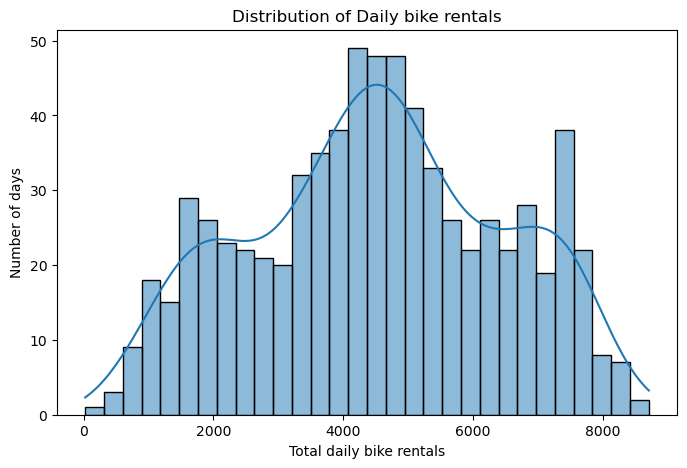

In [19]:
## Daily Rental Count Distribution

plt.figure(figsize=(8,5))
sns.histplot(data=day_df,x="cnt",bins=30,kde=True)
plt.title("Distribution of Daily bike rentals")
plt.xlabel("Total daily bike rentals")
plt.ylabel("Number of days")
plt.show()

Most days had approximately 4,000 to 5,000 rentals. The distribution is not perfectly bell-shaped, so I will further investigate how seasonality and weather conditions affect rental demand.

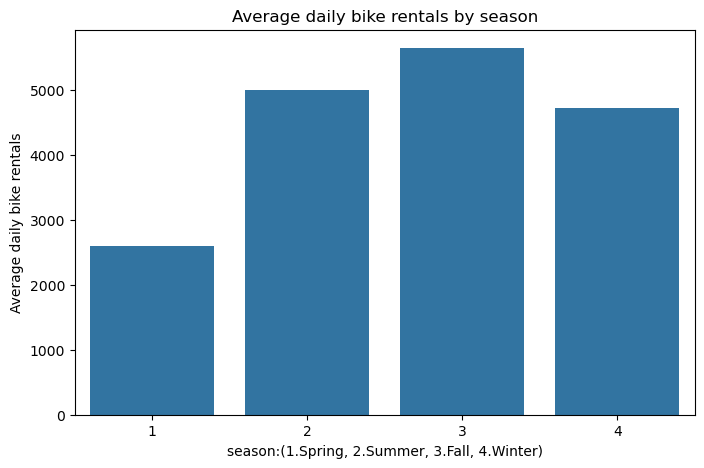

In [20]:
# Season-wise rentals
plt.figure(figsize=(8,5))
sns.barplot(data=day_df, x="season",y="cnt",errorbar=None)
plt.title("Average daily bike rentals by season")
plt.xlabel("season:(1.Spring, 2.Summer, 3.Fall, 4.Winter)")
plt.ylabel("Average daily bike rentals")
plt.show()

I used a bar plot to compare average daily bike rentals across seasons. Fall had the highest average rentals, while spring had the lowest. This suggests that seasonality may be an important factor in predicting bike rental demand.

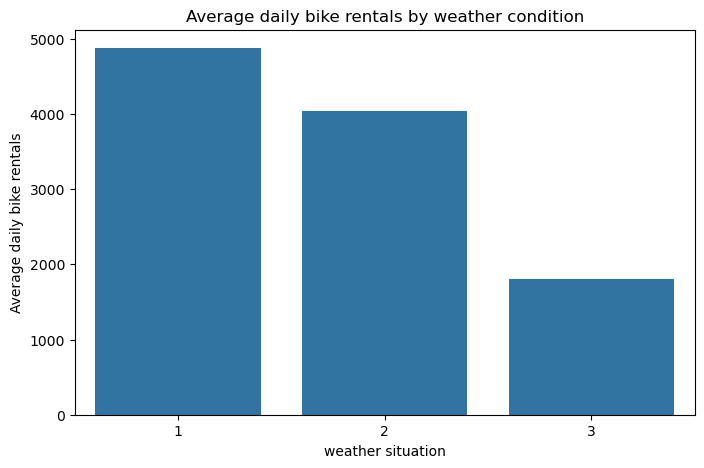

In [21]:
# Weather ka effect
plt.figure(figsize=(8,5))
sns.barplot(data=day_df,x="weathersit",y="cnt",errorbar=None)
plt.title("Average daily bike rentals by weather condition")
plt.xlabel("weather situation")
plt.ylabel("Average daily bike rentals")
plt.show()

Rentals were highest in clear weather and lowest in weather category 3. This suggests that weather conditions may influence bike rental demand and could be useful features for prediction.

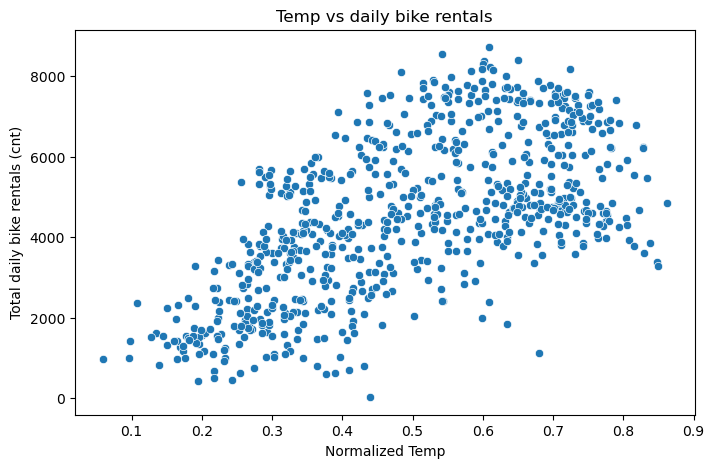

In [22]:
# Temperature ka effect
plt.figure(figsize=(8,5))
sns.scatterplot(data=day_df,x="temp",y="cnt")
plt.title("Temp vs daily bike rentals")
plt.xlabel("Normalized Temp")
plt.ylabel("Total daily bike rentals (cnt)")
plt.show()

I used a scatter plot to study the relationship between temperature and daily bike rentals. The plot shows a generally positive relationship: rentals tend to increase as temperature rises. However, the variation in rental counts suggests that other factors, such as season and weather, may also influence demand.

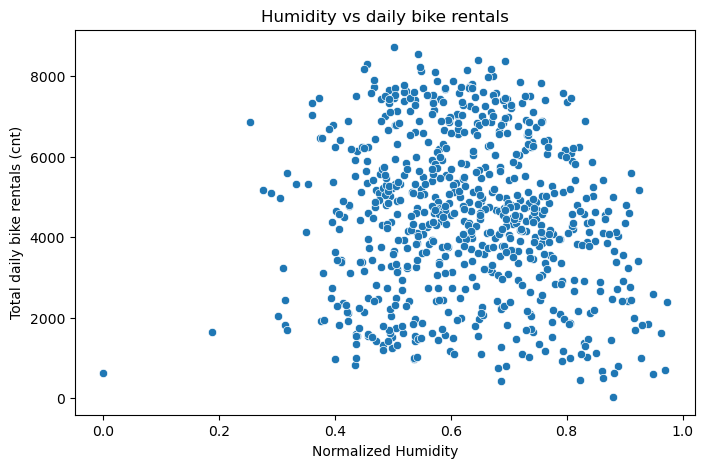

In [23]:
# Humidity vs Daily Bike Rentals
plt.figure(figsize=(8,5))
sns.scatterplot(data=day_df,x="hum",y="cnt")
plt.title("Humidity vs daily bike rentals")
plt.xlabel("Normalized Humidity")
plt.ylabel("Total daily bike rentals (cnt)")
plt.show()

The plot suggests a possible negative relationship, but there is substantial variation in rental counts at similar humidity levels. Therefore, humidity alone may not be sufficient to predict demand.

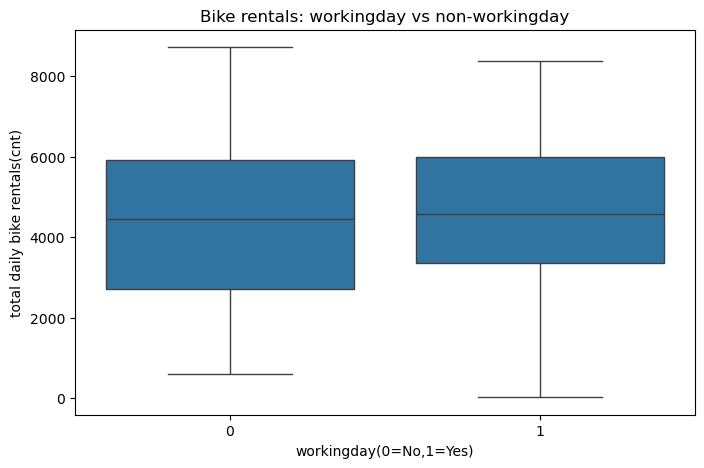

In [24]:
# Working Day vs Non-Working Day
plt.figure(figsize=(8,5))
sns.boxplot(data=day_df,x="workingday",y="cnt")
plt.title("Bike rentals: workingday vs non-workingday")
plt.xlabel("workingday(0=No,1=Yes)")
plt.ylabel("total daily bike rentals(cnt)")
plt.show()

Rentals are almost similar in both groups. So, whether it is a working day or not is not the only factor that affects bike rentals.

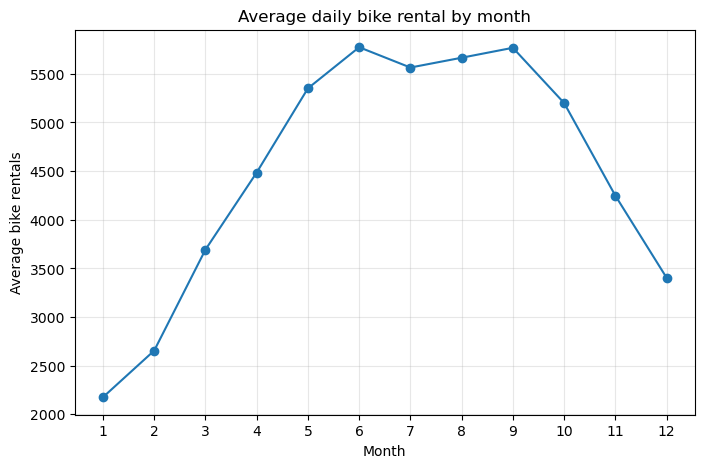

In [25]:
# Monthly Bike Rental Trend
monthly_rentals=day_df.groupby("mnth")["cnt"].mean()
plt.figure(figsize=(8,5))
plt.plot(monthly_rentals.index,monthly_rentals.values,marker="o")
plt.title("Average daily bike rental by month")
plt.xlabel("Month")
plt.ylabel("Average bike rentals")
plt.xticks(range(1,13))
plt.grid(True, alpha=0.3)
plt.show()

Rentals generally increased from January to June, remained high during summer, and declined toward the end of the year. This indicates a seasonal pattern in bike rental demand.

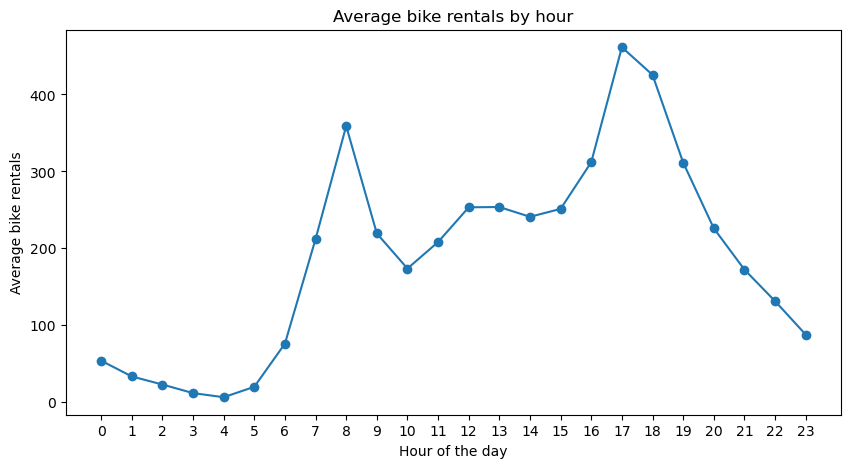

In [26]:
# Hourly Dataset Analysis
hourly_rentals = hour_df.groupby("hr")["cnt"].mean()
plt.figure(figsize=(10,5))
plt.plot(hourly_rentals.index, hourly_rentals.values, marker="o")
plt.title("Average bike rentals by hour")
plt.xlabel("Hour of the day")
plt.ylabel("Average bike rentals")
plt.xticks(range(0,24))
plt.show()

Rentals were very low during early morning hours, increased sharply around 7–8 AM, and reached the highest level around 5 PM. This shows that bike rental demand varies by time of day, with clear morning and evening peaks.

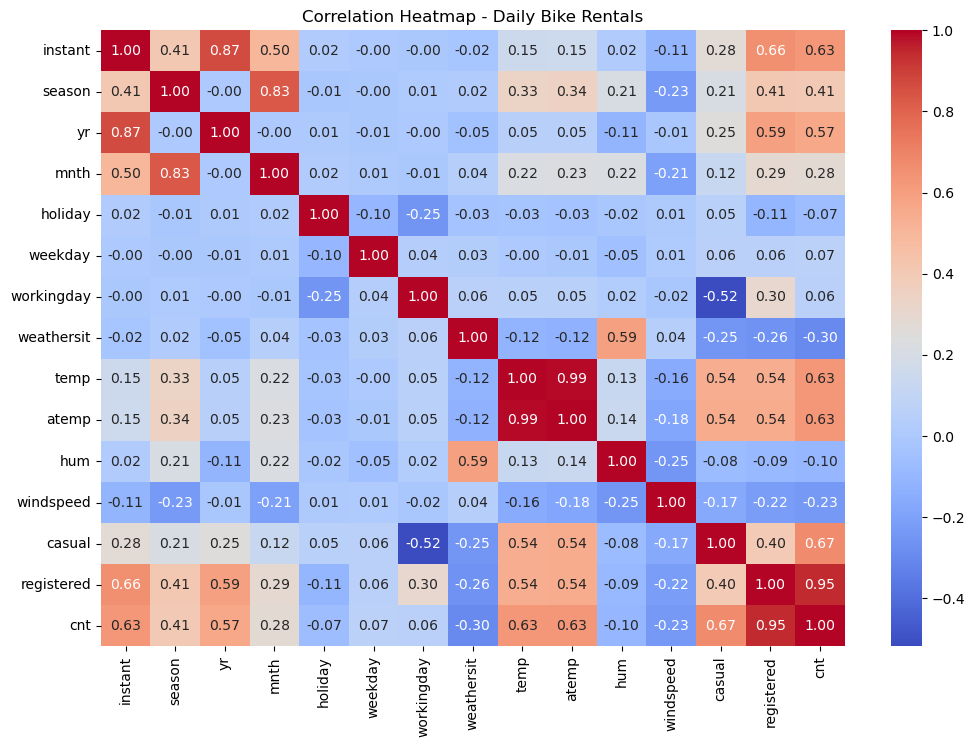

In [27]:
# 1. Correlation Heatmap
plt.figure(figsize=(12, 8))

corr = day_df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Daily Bike Rentals")
plt.show()

### Observation – Correlation Heatmap

1. Temperature (`temp`) and feeling temperature (`atemp`) show a positive correlation with total bike rentals (`cnt`), both approximately 0.63.
2. The year variable (`yr`) has a positive correlation of approximately 0.57 with bike rentals.
3. Weather situation (`weathersit`) shows a negative correlation of approximately -0.30 with rentals.
4. Humidity (`hum`) and windspeed show weak negative correlations with rentals.
5. The `casual` and `registered` columns have high correlations with `cnt`, but they will be excluded from model input because they are components of the target variable.
6. `temp` and `atemp` are highly correlated with each other (approximately 0.99), indicating potential multicollinearity.

**Conclusion:** Temperature, year, and weather-related variables may be useful for understanding rental demand. Feature selection and model evaluation will determine their usefulness for prediction.

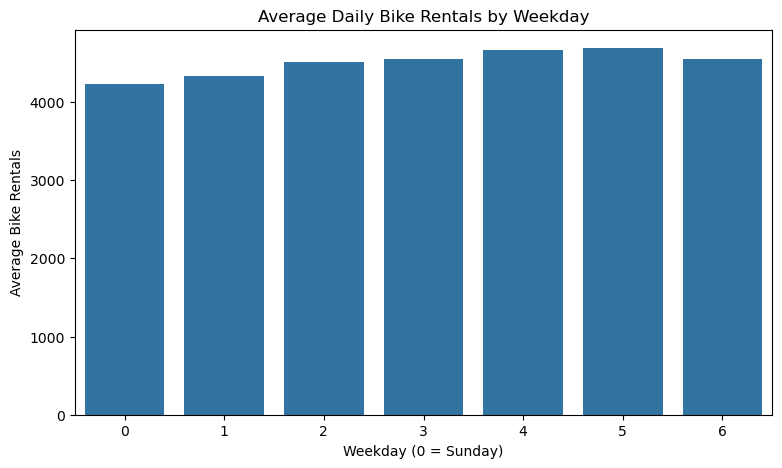

In [28]:
# 2. Average Daily Bike Rentals by Weekday
plt.figure(figsize=(9, 5))

weekday_rentals = day_df.groupby("weekday")["cnt"].mean()

sns.barplot(
    x=weekday_rentals.index,
    y=weekday_rentals.values
)

plt.title("Average Daily Bike Rentals by Weekday")
plt.xlabel("Weekday (0 = Sunday)")
plt.ylabel("Average Bike Rentals")

plt.show()

### Observation – Average Daily Bike Rentals by Weekday

1. Average bike rentals are lowest on Sunday (`weekday = 0`).
2. Average rentals increase from Sunday through Friday.
3. Friday (`weekday = 5`) shows the highest average rental demand in the graph.
4. Saturday (`weekday = 6`) shows a slight decrease compared with Friday.
5. The differences in average rentals across weekdays are relatively small.

**Conclusion:** Weekday may provide useful information about rental demand, although its relationship with total rentals is weak in the correlation heatmap.

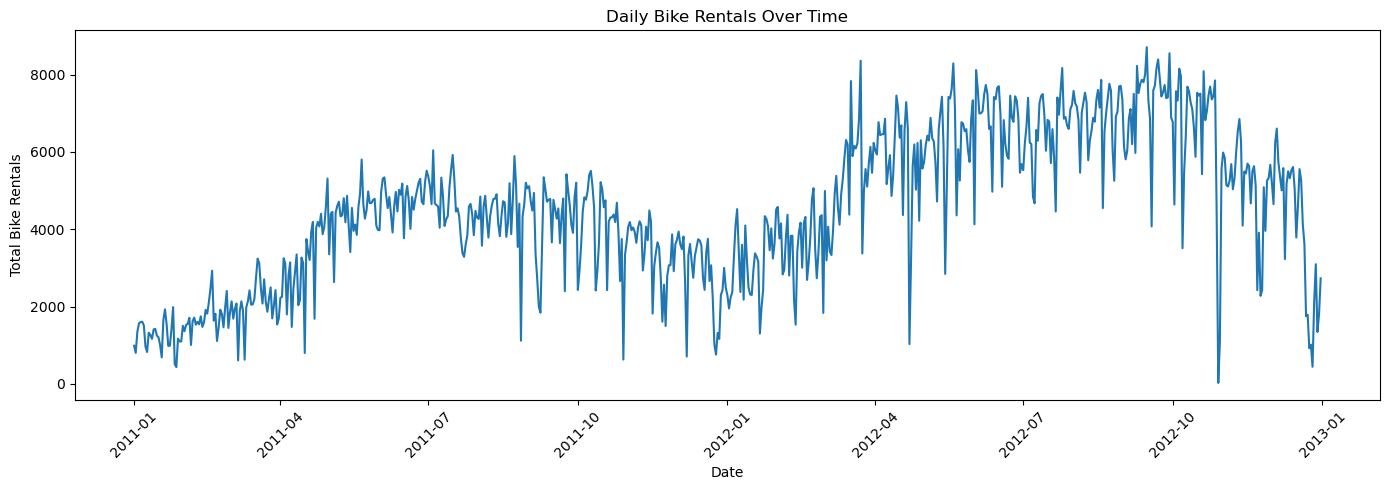

In [29]:
# 3. Daily Bike Rentals Over Time
plt.figure(figsize=(14, 5))

daily_rentals = day_df.sort_values("dteday")

plt.plot(
    daily_rentals["dteday"],
    daily_rentals["cnt"]
)

plt.title("Daily Bike Rentals Over Time")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation – Daily Bike Rentals Over Time

1. Bike rental demand generally increases during the first half of 2011.
2. Rental counts decrease during parts of late 2011.
3. In 2012, rental demand is generally higher, with several days reaching approximately 6,000–8,000 rentals.
4. Demand decreases toward the end of 2012.
5. The graph shows noticeable fluctuations and possible seasonal patterns.

**Conclusion:** Daily bike rental demand changes over time and appears to follow a seasonal pattern. Date-related features and weather conditions may help explain these changes.

## EDA Summary and Key Findings

The exploratory data analysis revealed the following patterns:

1. Daily bike rental demand varies over time and shows seasonal fluctuations.
2. Temperature and feeling temperature have a positive relationship with total rentals.
3. Poorer weather conditions generally show lower average rental demand.
4. Rental demand varies across seasons, months, weekdays, and working days.
5. The correlation heatmap helps identify relationships between numerical variables.
6. The `casual` and `registered` columns contribute directly to `cnt` and must be excluded from model input to avoid target leakage.

**Conclusion:** EDA provides useful insights into bike rental demand and helps guide feature selection and model development.

## 9. Feature Selection

Feature selection identifies the input variables used to predict the target variable.

- **Target (`y`):** `cnt` — total bike rentals.
- **Input features (`X`):** Calendar-related variables (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`), weather situation (`weathersit`), and weather measurements (`temp`, `atemp`, `hum`, `windspeed`).
- `instant` is excluded because it is an identifier.
- `casual` and `registered` are excluded because they directly contribute to `cnt`, which would cause target leakage.

The daily dataset is used to build the daily rental prediction model.

In [30]:
features = [
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

X = day_df[features]
y = day_df["cnt"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:", y.name)

Features shape: (731, 11)
Target shape: (731,)

Input features:
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

Target variable: cnt


## 10. Feature Type Identification

In this step, input features are grouped according to their data meaning and type.

- **Categorical features:** Represent categories such as season, month, weekday, and weather situation.
- **Numerical features:** Represent measurable values such as temperature, humidity, and windspeed.
- **Binary features:** Represent two possible values, such as 0 and 1.

Identifying feature types helps us choose suitable preprocessing techniques before model training.

In [31]:
categorical_features = [
    "season", "mnth", "weekday", "weathersit"
]

numerical_features = [
    "temp", "atemp", "hum", "windspeed"
]

binary_features = [
    "yr", "holiday", "workingday"
]

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)
print("Binary Features:", binary_features)

print("\nTotal features:",
      len(categorical_features)
      + len(numerical_features)
      + len(binary_features))

Categorical Features: ['season', 'mnth', 'weekday', 'weathersit']
Numerical Features: ['temp', 'atemp', 'hum', 'windspeed']
Binary Features: ['yr', 'holiday', 'workingday']

Total features: 11


## 11. Chronological Train-Test Split

In this step, the daily dataset is sorted by date and divided into training and testing sets in chronological order.

- **Training set (80%):** Used to train the model on earlier dates.
- **Testing set (20%):** Used to evaluate the model on later dates.

A chronological split provides a more realistic evaluation for predicting future bike rental demand.

In [32]:
# Sort data by date
day_df = day_df.sort_values("dteday").reset_index(drop=True)

# 80% training and 20% testing
split_index = int(len(day_df) * 0.80)

X_train = day_df[features].iloc[:split_index]
y_train = day_df["cnt"].iloc[:split_index]

X_test = day_df[features].iloc[split_index:]
y_test = day_df["cnt"].iloc[split_index:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining date range:")
print(day_df["dteday"].iloc[0], "to",
      day_df["dteday"].iloc[split_index - 1])

print("\nTesting date range:")
print(day_df["dteday"].iloc[split_index], "to",
      day_df["dteday"].iloc[-1])

Training features: (584, 11)
Testing features: (147, 11)

Training date range:
2011-01-01 00:00:00 to 2012-08-06 00:00:00

Testing date range:
2012-08-07 00:00:00 to 2012-12-31 00:00:00


###  12: Data Preprocessing

Data preprocessing prepares the input features for machine learning.

- **One-Hot Encoding:** Converts categorical variables into numerical columns.
- **Standard Scaling:** Scales numerical features to a comparable range.
- **Passthrough:** Keeps binary features unchanged.
- **ColumnTransformer:** Applies different preprocessing steps to different feature types.
- **Pipeline:** Combines preprocessing and the machine learning model into one workflow.

The preprocessing steps will be fitted on the training data only to prevent data leakage.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline

In [34]:
# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(handle_unknown="ignore")
# Preprocessing for numerical features
numerical_transformer = StandardScaler()
# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("cat",categorical_transformer,categorical_features),
        ("num",numerical_transformer,numerical_features),
        ("binary","passthrough",binary_features)
    ]
)
print("preprocessor created successfully")

preprocessor created successfully


###  13: Model Building and Training

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

In this project, it will learn patterns from historical bike rental data to predict total daily rentals (`cnt`).

A Pipeline combines preprocessing and the machine learning model into a single workflow.

In [35]:
from sklearn.linear_model import LinearRegression


In [36]:
# create the ML pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
]
)

In [37]:
# Train the model
model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
# predict bike rental on test data
y_pred = model.predict(X_test)
# first 10 predicted values
y_pred[:10].round(0)

array([6492., 6556., 6935., 6102., 6053., 6653., 6779., 6697., 6658.,
       6927.])

In [39]:
# first 10 actual values
print(y_test.head(10).values)

[7273 7534 7286 5786 6299 6544 6883 6784 7347 7605]


In [40]:
from sklearn.metrics import mean_absolute_error,r2_score,mean_squared_error
import numpy as np

In [41]:
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

print("MAE:",round(mae,2))
print("RMSE:",round(rmse,2))
print("R2 score:",round(r2,2))

MAE: 803.63
RMSE: 1102.66
R2 score: 0.65


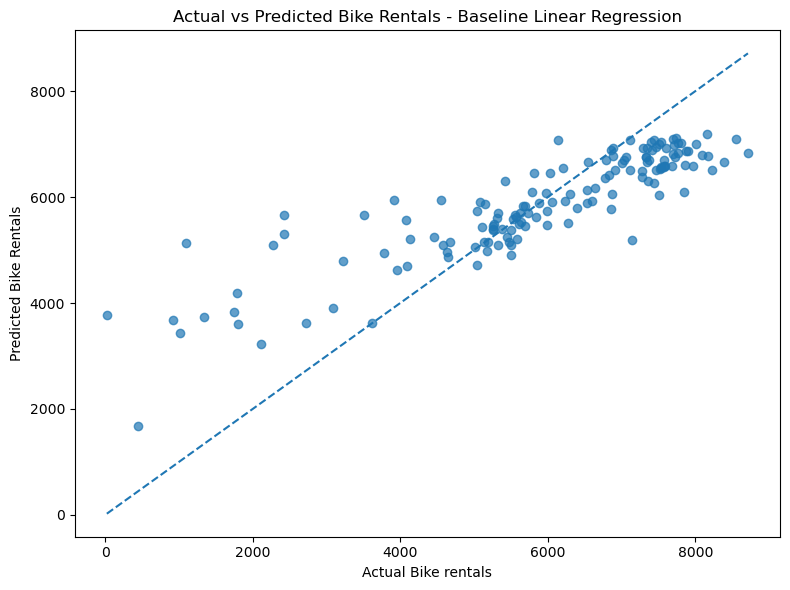

In [42]:
# Baseline model: Linear Regression
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred,alpha=0.7)
# perfect predictions ki reference line
min_value = min(y_test.min(),y_pred.min())
max_value = max(y_test.max(),y_pred.max())
plt.plot(
    [min_value,max_value],
    [min_value,max_value],
    linestyle="--"
)
plt.xlabel("Actual Bike rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals - Baseline Linear Regression")
plt.tight_layout()
plt.show()

### Interpretation:
- The graph compares actual bike rentals with predicted bike rentals.
- The dashed line represents perfect predictions.
- Points closer to the line indicate more accurate predictions.
- Some points are far from the line, indicating prediction errors.
- The model achieved an R² score of 0.65.

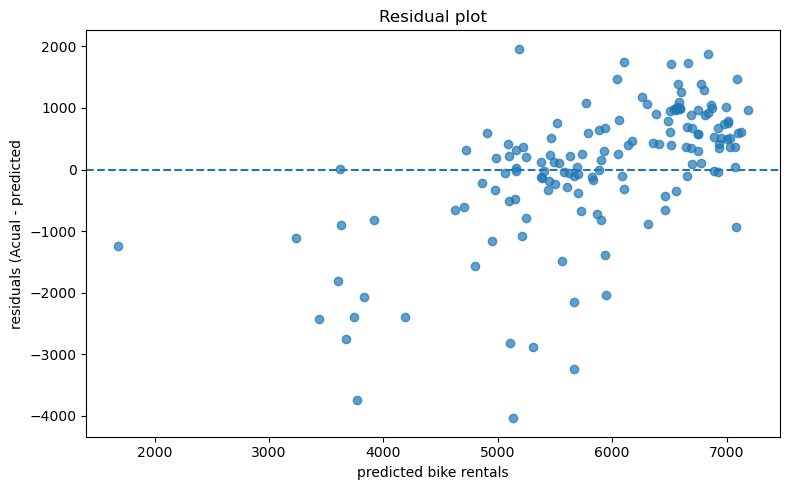

In [43]:
import matplotlib.pyplot as plt
residuals = y_test - y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred,residuals,alpha=0.7)
plt.axhline(y=0,linestyle="--")

plt.xlabel("predicted bike rentals")
plt.ylabel("residuals (Acual - predicted")
plt.title("Residual plot")
plt.tight_layout()
plt.show()

### Interpretation:
- Residual = Actual Rentals - Predicted Rentals.
- Positive residuals indicate underprediction, while negative residuals indicate overprediction.
- Some residuals are far from zero, indicating large prediction errors.
- The residual spread varies across predicted values, suggesting possible non-constant error variance.
- The model may be improved further.

In [44]:
print("Mean residual:",round(residuals.mean(),2))
print("Minimum residual:",round(residuals.min(),2))
print("Maximum residual:",round(residuals.max(),2))

Mean residual: 20.16
Minimum residual: -4040.03
Maximum residual: 1960.33


### Decision Tree hyperparameter Tuning


In [45]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

In [46]:
dt_model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",DecisionTreeRegressor(max_depth=5,min_samples_split=10,min_samples_leaf=5,random_state=42))
])

In [47]:
dt_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
dt_pred = dt_model.predict(X_test)
dt_mae = mean_absolute_error(y_test,dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test,dt_pred))
dt_r2 = r2_score(y_test,dt_pred)

print("Decision Tree MAE:",round(dt_mae,2))
print("Decision Tree RMSE:", round(dt_rmse,2))
print("Decision Tree R2:", round(dt_r2,2))

Decision Tree MAE: 976.04
Decision Tree RMSE: 1245.97
Decision Tree R2: 0.56


### Decision Tree Model Interpretation
- Decision Tree achieved an R² score of 0.56.
- Its MAE and RMSE are higher than Linear Regression.
- Linear Regression performed better on the current test set.
- Decision Tree may require hyperparameter tuning to improve its performance.

## Random Forest Hyperparameter Tuning


In [49]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

In [50]:
rf_model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",RandomForestRegressor(n_estimators=200,max_depth=8,min_samples_split=10,min_samples_leaf=5,random_state=42))
])

In [51]:
rf_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [52]:
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test,rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test,rf_pred))
rf_r2 = r2_score(y_test,rf_pred)

print("Random Forest MAE:",round(rf_mae,2))
print("Random Forest RMSE:",round(rf_rmse,2))
print("Random Forest R2:",round(rf_r2,2))

Random Forest MAE: 1058.93
Random Forest RMSE: 1269.63
Random Forest R2: 0.54


# Ridge


In [53]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

In [54]:
ridge_model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",Ridge(alpha=1.0))
])

In [55]:
ridge_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [56]:
ridge_pred = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test,ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test,ridge_pred))
ridge_r2 = r2_score(y_test,ridge_pred)

print("Ridge MAE:",round(ridge_mae,2))
print("Ridge RMSE:",round(ridge_rmse,2))
print("Ridge R2:", round(ridge_r2,2))

Ridge MAE: 812.68
Ridge RMSE: 1103.35
Ridge R2: 0.65


# Gradient Boosting Regressor


In [57]:
from sklearn.ensemble import GradientBoostingRegressor


In [58]:
gb_model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",GradientBoostingRegressor(n_estimators=100,learning_rate=0.05,max_depth=3,random_state=42))
])

In [59]:
gb_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [60]:
gb_pred = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test,gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test,gb_pred))
gb_r2 = r2_score(y_test,gb_pred)

print("Gradient Boosting MAE:",round(gb_mae,2))
print("Gradient Boosting RMSE:",round(gb_rmse,2))
print("Gradient Boosting R2:",round(gb_r2,4))

Gradient Boosting MAE: 1013.11
Gradient Boosting RMSE: 1179.63
Gradient Boosting R2: 0.604


# support vector machine


In [61]:
from sklearn.svm import SVR


In [62]:
svr_model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",SVR(kernel="rbf",C=100,epsilon=0.1))
])

In [63]:
svr_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [64]:
svr_pred = svr_model.predict(X_test)

svr_mae = mean_absolute_error(y_test,svr_pred)
svr_rmse = np.sqrt(mean_squared_error(y_test,svr_pred))
svr_r2 = r2_score(y_test,svr_pred)

print("SVM MAE:",round(svr_mae,2))
print("SVM RMSE:",round(svr_rmse,2))
print("SVM R2:",round(svr_r2,4))

SVM MAE: 1579.37
SVM RMSE: 1712.82
SVM R2: 0.1652


# KNN


In [65]:
from sklearn.neighbors import KNeighborsRegressor

In [66]:
knn_model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",KNeighborsRegressor(n_neighbors=5))
])

In [67]:
knn_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [68]:
knn_pred = knn_model.predict(X_test)

knn_mae = mean_absolute_error(y_test,knn_pred)
knn_rmse = np.sqrt(mean_squared_error(y_test,knn_pred))
knn_r2 = r2_score(y_test,knn_pred)

print("KNN MAE:",round(knn_mae,2))
print("KNN RMSE:",round(knn_rmse,2))
print("KNN R2:",round(knn_r2,2))

KNN MAE: 1781.01
KNN RMSE: 1987.16
KNN R2: -0.12



## Model Comparison

We evaluated multiple regression models using MAE, RMSE, and R² Score.

- MAE: Lower values indicate better predictions.
- RMSE: Lower values indicate fewer large prediction errors.
- R² Score: Higher values generally indicate better model performance.


# store predictions from all trained models


In [69]:
import pandas as pd 
import numpy as np
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

In [70]:
predictions={
    "Linear Regression":y_pred,
    "Decision Tree":dt_pred,
    "Random forest":rf_pred,
    "Ridge Regression":ridge_pred,
    "Gradient Boosting":gb_pred,
    "SVM":svr_pred,
    "KNN":knn_pred
}
results=[]
for model_name,y_prediction in predictions.items():
    mae=mean_absolute_error(y_test,y_prediction)
    rmse=np.sqrt(mean_squared_error(y_test,y_prediction))
    r2=r2_score(y_test,y_prediction)

    results.append({
        "model":model_name,
        "mae":round(mae,2),
        "rmse":round(rmse,2),
        "r2":round(r2,2)
    })

comparison_df=pd.DataFrame(results)
comparison_df=comparison_df.sort_values(by="mae",ascending=True).reset_index(drop=True)
comparison_df


,model,mae,rmse,r2
0,Linear Regression,803.63,1102.66,0.65
1,Ridge Regression,812.68,1103.35,0.65
2,Decision Tree,976.04,1245.97,0.56
3,Gradient Boosting,1013.11,1179.63,0.60
4,Random forest,1058.93,1269.63,0.54
5,SVM,1579.37,1712.82,0.17
6,KNN,1781.01,1987.16,-0.12


### Initial Model Comparison and Selection

Seven regression models were initially evaluated using MAE, RMSE, and R² score.

Linear Regression achieved an MAE of 803.63, RMSE of 1102.66, and R² score of approximately 0.65. It provided a useful baseline model. The initial results also showed that model performance varied across the selected evaluation metrics.

Further hyperparameter tuning and evaluation were performed to investigate whether predictive performance could be improved.

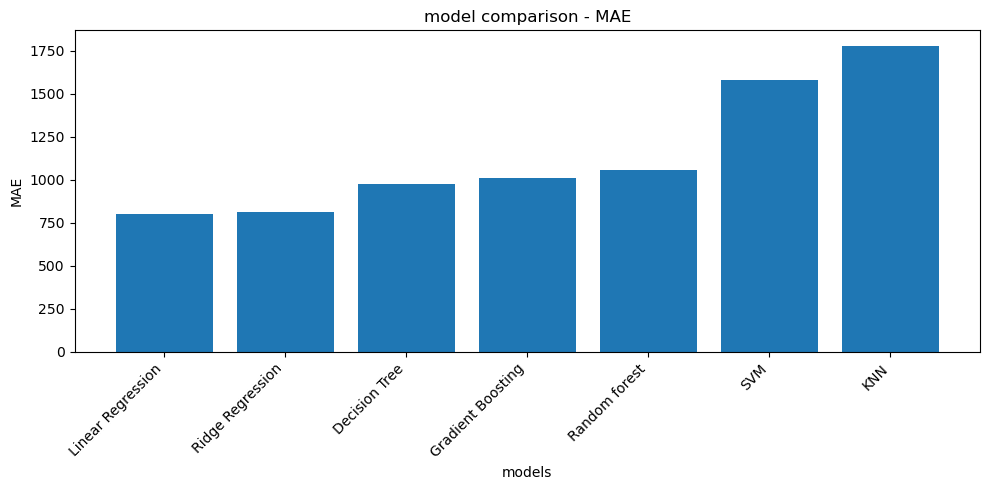

In [71]:
import matplotlib.pyplot as plt

# MAE comparison
plt.figure(figsize=(10,5))
plt.bar(comparison_df["model"],comparison_df["mae"])
plt.title("model comparison - MAE")
plt.xlabel("models")
plt.ylabel("MAE")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()



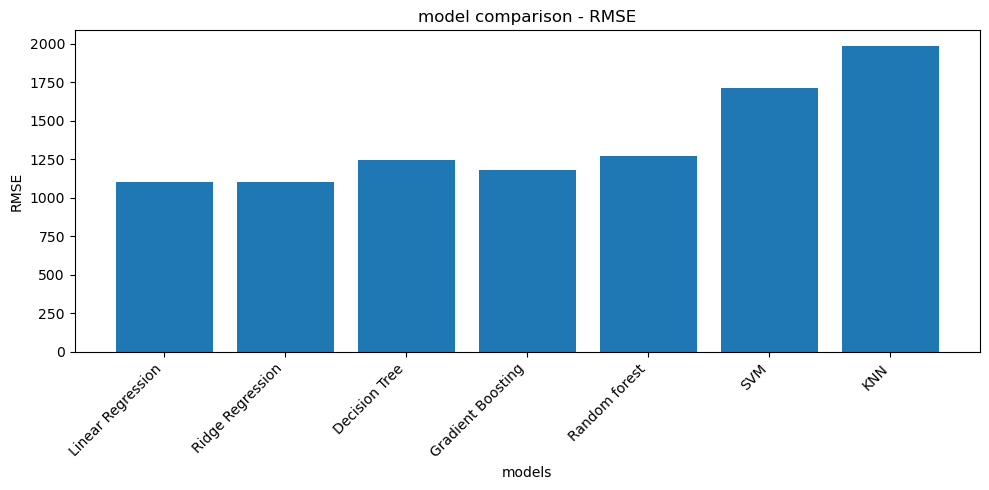

In [72]:
# RMSE comparison
plt.figure(figsize=(10,5))
plt.bar(comparison_df["model"],comparison_df["rmse"])
plt.title("model comparison - RMSE")
plt.xlabel("models")
plt.ylabel("RMSE")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

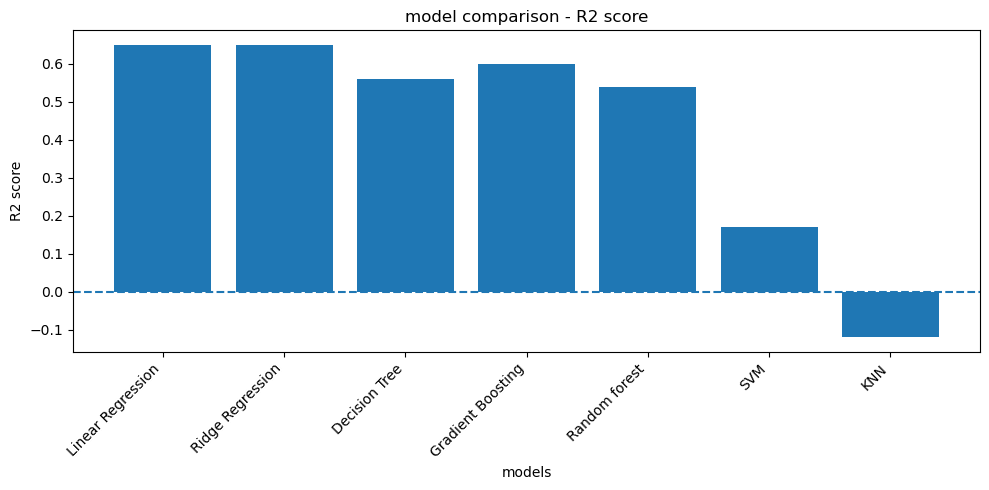

In [73]:
# R2 score comparison
plt.figure(figsize=(10,5))
plt.bar(comparison_df["model"],comparison_df["r2"])
plt.title("model comparison - R2 score")
plt.xlabel("models")
plt.ylabel("R2 score")
plt.xticks(rotation=45,ha="right")
plt.axhline(y=0,linestyle="--")
plt.tight_layout()
plt.show()

### Model Comparison – Graph Interpretation

- MAE compares the average absolute prediction error; lower values are better.
- RMSE penalizes larger prediction errors more strongly; lower values are better.
- R² measures the proportion of variation in daily rental counts explained by the model; higher values are generally better.
- KNN showed weak performance in the initial comparison, including a negative R² score.
- The initial model comparison was followed by hyperparameter tuning and a separate evaluation of tuned models.

The final model should be selected using the updated comparison table and the metric most relevant to the prediction task.

### Hyperparameter Tuning


In [74]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

param_grid = {
    "regressor__fit_intercept": [True, False],
    "regressor__positive": [True, False]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid_search_lr.fit(X_train, y_train)

print("Best Parameters:", grid_search_lr.best_params_)
print("Best CV MAE:", round(-grid_search_lr.best_score_, 2))


Best Parameters: {'regressor__fit_intercept': True, 'regressor__positive': False}
Best CV MAE: 822.0


In [75]:
best_lr_model = grid_search_lr.best_estimator_
tuned_lr_pred = best_lr_model.predict(X_test)
print("Tuned LR MAE:",round(mean_absolute_error(y_test,tuned_lr_pred),2))
print("Tuned LR RMSE:",round(np.sqrt(mean_squared_error(y_test,tuned_lr_pred)),2))
print("Tuned LR R2:",round(r2_score(y_test,tuned_lr_pred),4))

Tuned LR MAE: 803.63
Tuned LR RMSE: 1102.66
Tuned LR R2: 0.654


### Linear Regression Hyperparameter Tuning

GridSearchCV with TimeSeriesSplit was used to evaluate different Linear Regression configurations. The search considered `fit_intercept` and `regressor_positive`.

The tuned model's test-set performance was compared with the original Linear Regression model using MAE, RMSE, and R² score. The tuning results indicate whether the tested configurations improved performance on the held-out test period.

### Hyperparameter Tuning Ridge Regression


In [76]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

param_grid = {
    "regressor__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid_search_ridge.fit(X_train, y_train)

print("Best Parameters:", grid_search_ridge.best_params_)
print("Best CV MAE:", round(-grid_search_ridge.best_score_, 2))


Best Parameters: {'regressor__alpha': 0.001}
Best CV MAE: 822.37


In [77]:

best_ridge_model = grid_search_ridge.best_estimator_

tuned_ridge_pred = best_ridge_model.predict(X_test)

tuned_ridge_mae = mean_absolute_error(y_test, tuned_ridge_pred)
tuned_ridge_rmse = np.sqrt(mean_squared_error(y_test, tuned_ridge_pred))
tuned_ridge_r2 = r2_score(y_test, tuned_ridge_pred)

print("Tuned Ridge MAE:", round(tuned_ridge_mae, 2))
print("Tuned Ridge RMSE:", round(tuned_ridge_rmse, 2))
print("Tuned Ridge R2:", round(tuned_ridge_r2, 4))


Tuned Ridge MAE: 803.63
Tuned Ridge RMSE: 1102.66
Tuned Ridge R2: 0.654


## Decision Tree


In [78]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

param_grid_dt = {
    "regressor__max_depth": [3, 5, 7, 10, None],
    "regressor__min_samples_split": [2, 5, 10, 20],
    "regressor__min_samples_leaf": [1, 2, 5, 10]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_dt,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid_search_dt.fit(X_train, y_train)

print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV MAE:", round(-grid_search_dt.best_score_, 2))

Best Parameters: {'regressor__max_depth': 5, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2}
Best CV MAE: 1099.11


In [79]:
best_dt_model = grid_search_dt.best_estimator_

tuned_dt_pred = best_dt_model.predict(X_test)

tuned_dt_mae = mean_absolute_error(y_test, tuned_dt_pred)
tuned_dt_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_dt_pred)
)
tuned_dt_r2 = r2_score(y_test, tuned_dt_pred)

print("Tuned Decision Tree MAE:", round(tuned_dt_mae, 2))
print("Tuned Decision Tree RMSE:", round(tuned_dt_rmse, 2))
print("Tuned Decision Tree R2:", round(tuned_dt_r2, 4))

Tuned Decision Tree MAE: 1018.88
Tuned Decision Tree RMSE: 1290.04
Tuned Decision Tree R2: 0.5264


In [80]:
# Random Forest Hyperparameter Tuning
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))
])

param_grid_rf = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [5, 8, 12],
    "regressor__min_samples_split": [2, 10],
    "regressor__min_samples_leaf": [2, 5]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid_search_rf.fit(X_train, y_train)

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV MAE:", round(-grid_search_rf.best_score_, 2))

Best Parameters: {'regressor__max_depth': 12, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
Best CV MAE: 1102.74


In [81]:
best_rf_model = grid_search_rf.best_estimator_

tuned_rf_pred = best_rf_model.predict(X_test)

tuned_rf_mae = mean_absolute_error(y_test, tuned_rf_pred)
tuned_rf_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_rf_pred)
)
tuned_rf_r2 = r2_score(y_test, tuned_rf_pred)

print("Tuned Random Forest MAE:", round(tuned_rf_mae, 2))
print("Tuned Random Forest RMSE:", round(tuned_rf_rmse, 2))
print("Tuned Random Forest R2:", round(tuned_rf_r2, 4))

Tuned Random Forest MAE: 1051.94
Tuned Random Forest RMSE: 1252.34
Tuned Random Forest R2: 0.5537


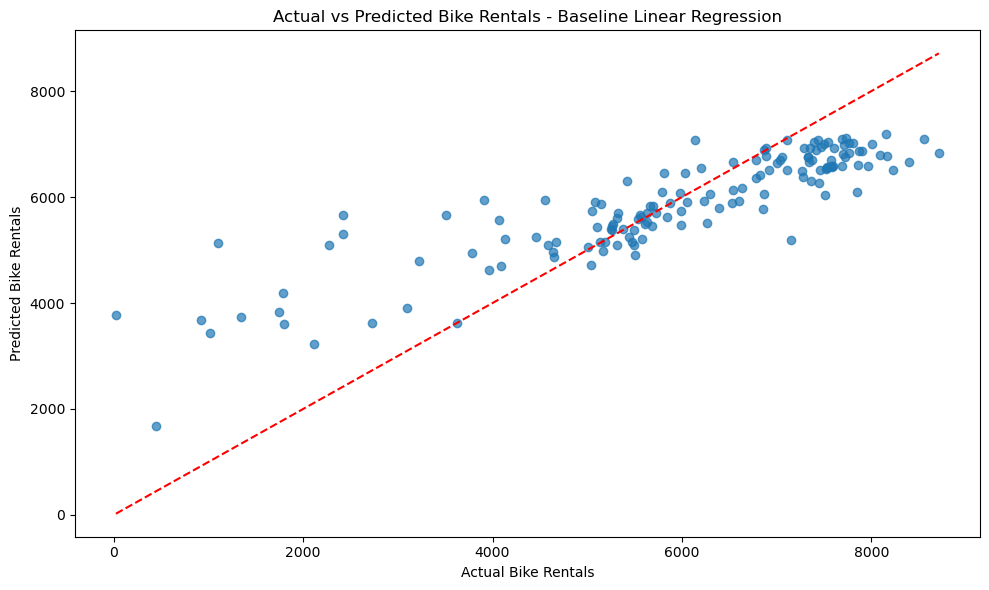

In [82]:
# Now compare best model predictions to actual rental counts
import matplotlib.pyplot as plt

# Baseline model: Linear Regression
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals - Baseline Linear Regression")
plt.tight_layout()
plt.show()

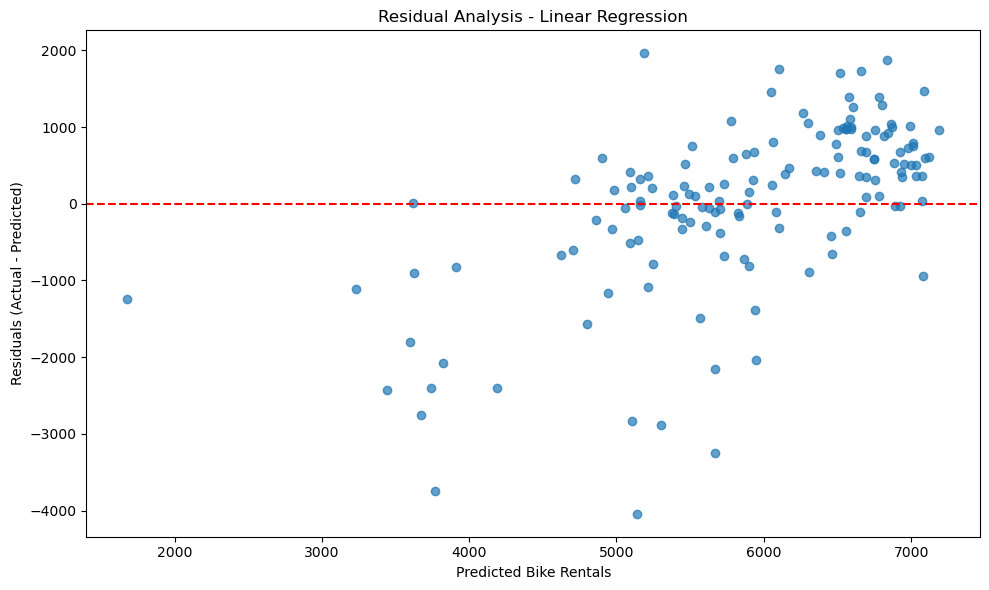

In [83]:
# Calculate residuals
residuals = y_test - y_pred

# Plot residuals
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Bike Rentals")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis - Linear Regression")
plt.tight_layout()
plt.show()

### Residual Analysis – Linear Regression

Residual analysis was performed using the difference between actual and predicted bike rental counts. Some predictions are close to the actual values, while several observations have large positive or negative residuals. This indicates that the model makes substantial errors for certain observations and may not capture every pattern in bike rental demand.

Linear Regression serves as a baseline model. The final model selection is based on the updated comparison of original and tuned models using MAE, RMSE, and R².

In [84]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(random_state=42))
])

param_grid_gb = {
    "regressor__n_estimators": [100, 200],
    "regressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__max_depth": [2, 3, 4],
    "regressor__min_samples_leaf": [3, 5]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search_gb = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid_gb,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid_search_gb.fit(X_train, y_train)

print("Best Parameters:", grid_search_gb.best_params_)
print("Best CV MAE:", round(-grid_search_gb.best_score_, 2))

Best Parameters: {'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__min_samples_leaf': 3, 'regressor__n_estimators': 200}
Best CV MAE: 956.57


In [85]:
best_gb_model = grid_search_gb.best_estimator_

tuned_gb_pred = best_gb_model.predict(X_test)

tuned_gb_mae = mean_absolute_error(y_test, tuned_gb_pred)
tuned_gb_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_gb_pred)
)
tuned_gb_r2 = r2_score(y_test, tuned_gb_pred)

print("Tuned Gradient Boosting MAE:", round(tuned_gb_mae, 2))
print("Tuned Gradient Boosting RMSE:", round(tuned_gb_rmse, 2))
print("Tuned Gradient Boosting R2:", round(tuned_gb_r2, 4))

Tuned Gradient Boosting MAE: 874.55
Tuned Gradient Boosting RMSE: 1041.33
Tuned Gradient Boosting R2: 0.6914


In [86]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Store predictions from all original models and tuned Gradient Boosting
predictions = {
    "Linear Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Ridge Regression": ridge_pred,
    "Gradient Boosting": gb_pred,
    "SVM": svr_pred,
    "KNN": knn_pred,
    "Tuned Gradient Boosting": tuned_gb_pred
}

# Calculate evaluation metrics
results = []

for model_name, y_prediction in predictions.items():
    mae = mean_absolute_error(y_test, y_prediction)
    rmse = np.sqrt(mean_squared_error(y_test, y_prediction))
    r2 = r2_score(y_test, y_prediction)

    results.append({
        "model": model_name,
        "mae": round(mae, 2),
        "rmse": round(rmse, 2),
        "r2": round(r2, 4)
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

# Sort models by MAE (lowest first)
comparison_df = comparison_df.sort_values(
    by="mae",
    ascending=True
).reset_index(drop=True)

# Display final comparison
comparison_df

,model,mae,rmse,r2
0,Linear Regression,803.63,1102.66,0.6540
1,Ridge Regression,812.68,1103.35,0.6536
2,Tuned Gradient Boosting,874.55,1041.33,0.6914
3,Decision Tree,976.04,1245.97,0.5582
4,Gradient Boosting,1013.11,1179.63,0.6040
5,Random Forest,1058.93,1269.63,0.5413
6,SVM,1579.37,1712.82,0.1652
7,KNN,1781.01,1987.16,-0.1237


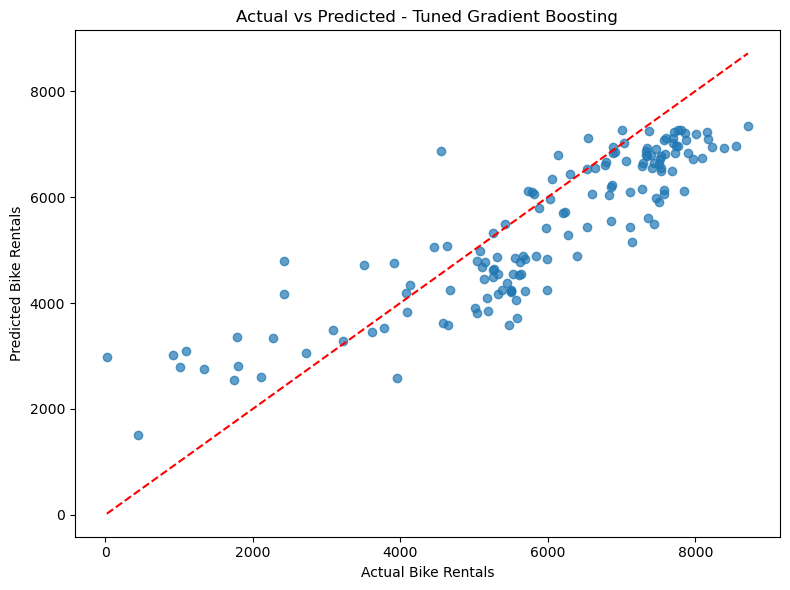

In [87]:
import matplotlib.pyplot as plt

# Actual vs Predicted
plt.figure(figsize=(8, 6))

plt.scatter(y_test, tuned_gb_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted - Tuned Gradient Boosting")
plt.tight_layout()
plt.show()

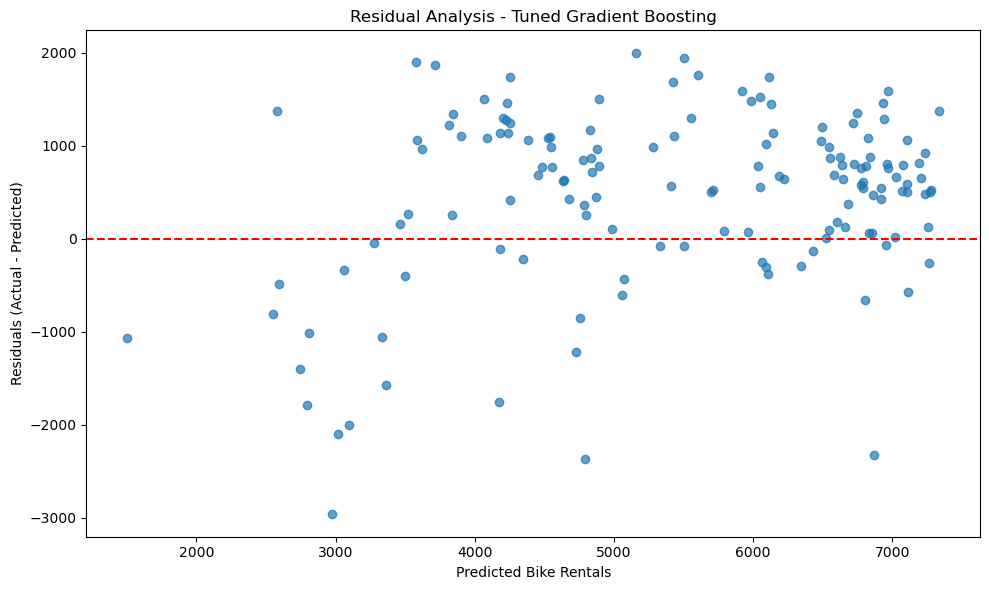

In [88]:
import matplotlib.pyplot as plt

# Calculate residuals
tuned_gb_residuals = y_test - tuned_gb_pred

# Residual plot
plt.figure(figsize=(10, 6))

plt.scatter(
    tuned_gb_pred,
    tuned_gb_residuals,
    alpha=0.7
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Bike Rentals")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis - Tuned Gradient Boosting")

plt.tight_layout()
plt.show()

### Residual Analysis – Tuned Gradient Boosting

The residual plot shows that residuals are distributed both above and below the zero line. Positive residuals indicate underprediction, while negative residuals indicate overprediction. Some observations have large residuals, suggesting that the model makes substantial prediction errors for certain days. Overall, the model captures useful patterns in bike rental demand, but its predictions can still be improved.

## Tuned KNN Model

In [89]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", KNeighborsRegressor())
])

# Parameters to test
param_grid_knn = {
    "regressor__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "regressor__weights": ["uniform", "distance"],
    "regressor__p": [1, 2]
}

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Grid Search
grid_search_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

# Train and tune
grid_search_knn.fit(X_train, y_train)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV MAE:", round(-grid_search_knn.best_score_, 2))

Best Parameters: {'regressor__n_neighbors': 5, 'regressor__p': 2, 'regressor__weights': 'distance'}
Best CV MAE: 1392.1


In [90]:
tuned_knn_model = grid_search_knn.best_estimator_

tuned_knn_pred = tuned_knn_model.predict(X_test)

tuned_knn_mae = mean_absolute_error(y_test, tuned_knn_pred)
tuned_knn_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_knn_pred)
)
tuned_knn_r2 = r2_score(y_test, tuned_knn_pred)

print("Tuned KNN Results")
print("MAE:", round(tuned_knn_mae, 2))
print("RMSE:", round(tuned_knn_rmse, 2))
print("R² Score:", round(tuned_knn_r2, 4))

Tuned KNN Results
MAE: 1776.99
RMSE: 1990.41
R² Score: -0.1273


## Tuned SVR Model

In [91]:
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create SVR pipeline
svr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", SVR())
])

# Parameters to test
param_grid_svr = {
    "regressor__kernel": ["rbf", "linear"],
    "regressor__C": [100, 500, 1000],
    "regressor__epsilon": [0.1, 0.5, 1.0]
}

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Grid Search
grid_search_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid_svr,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

# Train and tune
grid_search_svr.fit(X_train, y_train)

print("Best Parameters:", grid_search_svr.best_params_)
print("Best CV MAE:", round(-grid_search_svr.best_score_, 2))

Best Parameters: {'regressor__C': 1000, 'regressor__epsilon': 0.1, 'regressor__kernel': 'linear'}
Best CV MAE: 904.24


In [92]:
# Best SVR model
tuned_svr_model = grid_search_svr.best_estimator_

# Predictions
tuned_svr_pred = tuned_svr_model.predict(X_test)

# Evaluation
tuned_svr_mae = mean_absolute_error(y_test, tuned_svr_pred)
tuned_svr_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_svr_pred)
)
tuned_svr_r2 = r2_score(y_test, tuned_svr_pred)

print("Tuned SVM Results")
print("MAE:", round(tuned_svr_mae, 2))
print("RMSE:", round(tuned_svr_rmse, 2))
print("R² Score:", round(tuned_svr_r2, 4))

Tuned SVM Results
MAE: 818.32
RMSE: 1128.4
R² Score: 0.6377


## Original and tuned model predictions

In [93]:

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


predictions = {
    "Linear Regression": y_pred,
    "Ridge Regression": ridge_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred,
    "SVM": svr_pred,
    "KNN": knn_pred,
    "Tuned Linear Regression": tuned_lr_pred,
    "Tuned Ridge Regression": tuned_ridge_pred,
    "Tuned Decision Tree": tuned_dt_pred,
    "Tuned Random Forest": tuned_rf_pred,
    "Tuned Gradient Boosting": tuned_gb_pred,
    "Tuned SVM": tuned_svr_pred,
    "Tuned KNN": tuned_knn_pred
}

# Calculate evaluation metrics
results = []

for model_name, y_prediction in predictions.items():
    mae = mean_absolute_error(y_test, y_prediction)
    rmse = np.sqrt(mean_squared_error(y_test, y_prediction))
    r2 = r2_score(y_test, y_prediction)

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

# Create comparison table
comparison_df = pd.DataFrame(results)

comparison_df = (
    comparison_df
    .sort_values(by="MAE")
    .reset_index(drop=True)
)

display(comparison_df)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,803.63,1102.66,0.6540
1,Tuned Linear Regression,803.63,1102.66,0.6540
2,Tuned Ridge Regression,803.63,1102.66,0.6540
3,Ridge Regression,812.68,1103.35,0.6536
4,Tuned SVM,818.32,1128.40,0.6377
5,Tuned Gradient Boosting,874.55,1041.33,0.6914
6,Decision Tree,976.04,1245.97,0.5582
7,Gradient Boosting,1013.11,1179.63,0.6040
8,Tuned Decision Tree,1018.88,1290.04,0.5264
9,Tuned Random Forest,1051.94,1252.34,0.5537


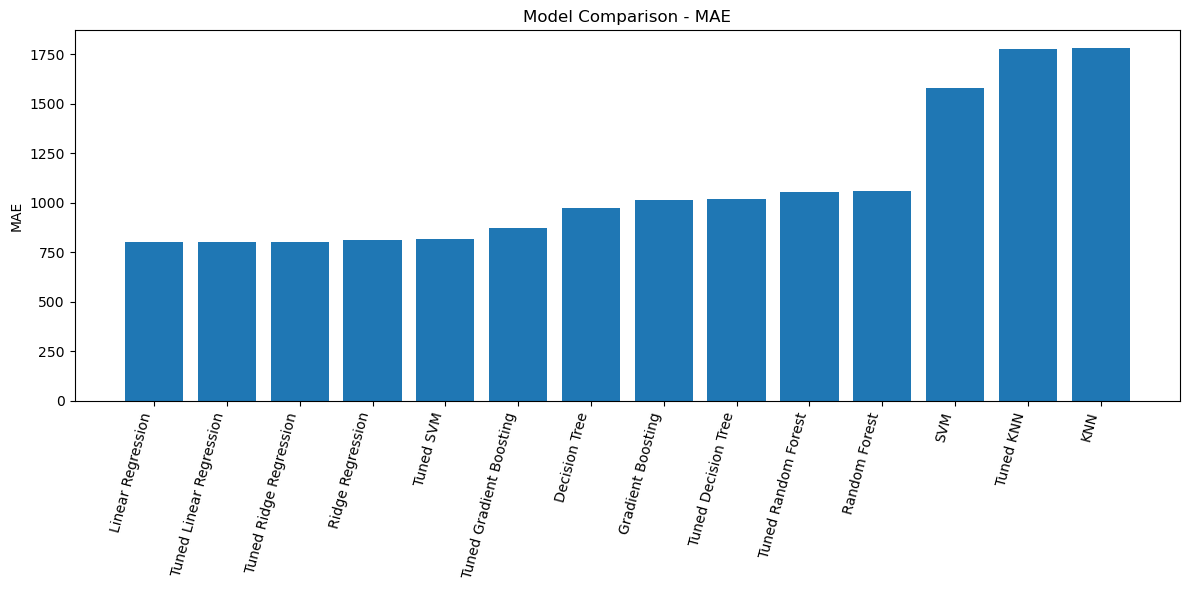

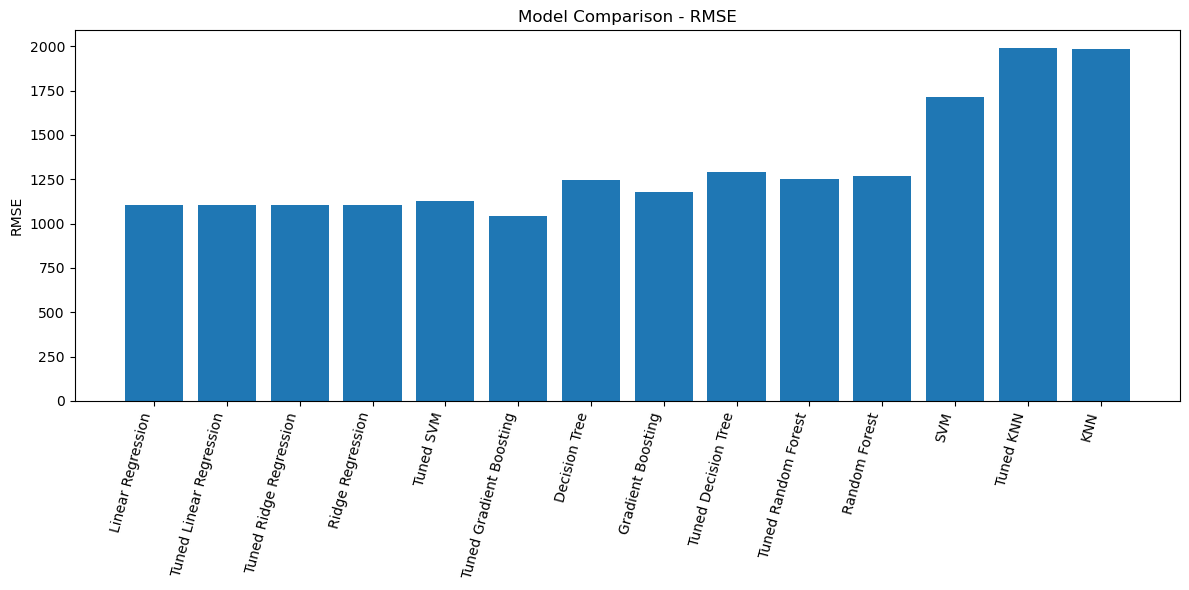

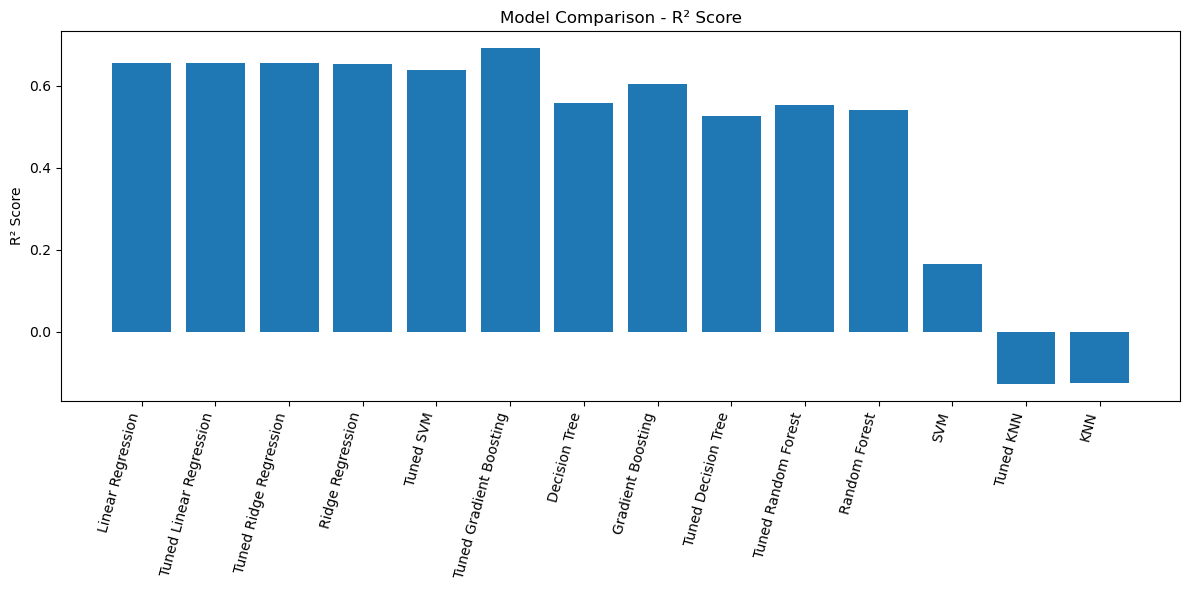

In [94]:

import matplotlib.pyplot as plt

# MAE Comparison
plt.figure(figsize=(12, 6))
plt.bar(comparison_df["Model"], comparison_df["MAE"])
plt.xticks(rotation=75, ha="right")
plt.ylabel("MAE")
plt.title("Model Comparison - MAE")
plt.tight_layout()
plt.show()

# RMSE Comparison
plt.figure(figsize=(12, 6))
plt.bar(comparison_df["Model"], comparison_df["RMSE"])
plt.xticks(rotation=75, ha="right")
plt.ylabel("RMSE")
plt.title("Model Comparison - RMSE")
plt.tight_layout()
plt.show()

# R2 Score Comparison
plt.figure(figsize=(12, 6))
plt.bar(comparison_df["Model"], comparison_df["R2 Score"])
plt.xticks(rotation=75, ha="right")
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")
plt.tight_layout()
plt.show()


### Model Comparison and Selection

Fourteen model entries were compared, including seven original models and seven tuned model configurations, using MAE, RMSE, and R² score.
- **Linear Regression** achieved an MAE of 803.63, making it the best model by this metric among the original models.
- **Tuned Gradient Boosting** achieved an RMSE of 1041.33 and an R² score of 0.6914 in the tuned model comparison.
- A lower MAE indicates smaller average absolute errors, while a lower RMSE indicates fewer large prediction errors. A higher R² indicates that the model explains more variation in daily rental counts.

Based on RMSE and R², Tuned Gradient Boosting was selected as the final candidate model. Linear Regression remains a useful baseline because of its lower MAE. The final choice should depend on the business cost of different prediction errors and should be validated on additional future data.

In [95]:

import joblib

# Save the complete tuned model pipeline
final_model = best_gb_model

joblib.dump(
    final_model,
    "bike_rental_model.pkl"
)

print("Final model saved successfully!")


Final model saved successfully!


In [96]:

import os

if os.path.exists("bike_rental_model.pkl"):
    print("Model file exists!")
    print("File size:", round(
        os.path.getsize("bike_rental_model.pkl") / 1024, 2
    ), "KB")
else:
    print("Model file not found.")


Model file exists!
File size: 154.79 KB


In [97]:

import joblib

loaded_model = joblib.load("bike_rental_model.pkl")

# Test prediction
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Sample predictions:", sample_prediction)


Sample predictions: [6582.6278129  6544.94045984 6643.84667276 6091.3261463  6432.24561854]


## Model Comparison Report

### Objective
The objective of this task is to compare multiple machine learning regression models and select the most suitable model for predicting daily bike rental demand.

### Models Evaluated
The following regression models were evaluated:

1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. Support Vector Regression (SVR)
7. K-Nearest Neighbors (KNN) Regressor

### Evaluation Metrics

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted bike rentals. Lower values are better.
- **RMSE (Root Mean Squared Error):** Penalizes large prediction errors more heavily. Lower values are better.
- **R² Score:** Measures how much variation in the target variable is explained by the model. Higher values are generally better.

### Results and Best Model

The tuned Gradient Boosting model achieved an MAE of 874.55, RMSE of 1041.33, and R² score of 0.6914.

Linear Regression achieved a lower MAE of 803.63, while Gradient Boosting achieved the lowest RMSE and highest R² among the reported results.

### Production Recommendation

Tuned Gradient Boosting is recommended as the final candidate because it achieved the lowest RMSE and highest R² among the reported models. However, Linear Regression achieved the lowest MAE, so model selection depends on the business cost of prediction errors.

Before production deployment, the selected model should be validated on additional unseen future data and monitored regularly for changes in demand patterns.

### Conclusion

Gradient Boosting provides a promising balance of predictive performance for this dataset. However, its predictions are not perfect, and further validation is required before real-world deployment.

## Report on Challenges Faced

### 1. Understanding Different Feature Types
**Challenge:** Some integer columns, such as `season`, `mnth`, and `weekday`, represent categories rather than continuous numerical measurements.

**Solution:** These features were manually classified using the dataset description. One-hot encoding was applied to selected categorical features.

**Reason:** This helps prevent the model from incorrectly interpreting category codes as continuous values.

### 2. Preventing Target Leakage
**Challenge:** The `casual` and `registered` columns directly contribute to the target variable `cnt`.

**Solution:** These columns were excluded from the model's input features.

**Reason:** Including them would allow the model to use information directly related to the target, resulting in unrealistic evaluation.

### 3. Preserving Time Order
**Challenge:** Randomly splitting time-dependent data could place future observations in the training set and earlier observations in the test set.

**Solution:** A chronological train-test split was used, with the first 584 observations for training and the remaining 147 observations for testing.

**Reason:** This better simulates predicting future bike rentals from historical data.

### 4. Handling Different Feature Scales
**Challenge:** Numerical features have different ranges and units.

**Solution:** StandardScaler was applied to the selected numerical features through a preprocessing pipeline.

**Reason:** Scaling can improve the behavior of scale-sensitive algorithms such as SVR and KNN.

### 5. Selecting the Best Model
**Challenge:** Different regression models produced different prediction errors.

**Solution:** Seven regression models were evaluated using MAE, RMSE, and R². Hyperparameter tuning was performed for selected models.

**Reason:** Comparing several metrics gives a more reliable basis for model selection than relying on a single score.

### 6. Improving Prediction Performance
**Challenge:** Some models produced large errors, and tuning did not improve every model.

**Solution:** Actual-versus-predicted plots, residual plots, and evaluation metrics were examined.

**Reason:** These checks help identify prediction errors and show where further improvement may be needed.

### 7. Limited Dataset Duration
**Challenge:** The daily dataset contains 731 observations from 2011 and 2012 only.

**Solution:** The available data was used for model development, and further validation on more recent data is recommended.

**Reason:** Demand patterns may change over time due to weather, events, infrastructure, and user behavior.

### Overall Conclusion
The challenges were addressed through feature classification, leakage prevention, chronological splitting, preprocessing pipelines, model comparison, and residual analysis. These techniques improved the reliability of the analysis, although additional validation is necessary before production use.